# EV demand

Per-year outputs of the `build_ev_demand` rule (`build/evs/ev_turnover.csv`,
indexed by year), from the fixed-retirement-age stock-turnover model. All
figures are read straight from that table — no calculation happens here.

1. **EV fleet on the road** — target EV stock filling up the (constant) car
   fleet as `land_transport_electric_share` rises.
2. **Annual EV turnover** — yearly sales, and the share of those sales that is
   just replacing the first cohort as it retires after `ev_lifetime_years`.
3. **Cumulative EV sales** — total vehicles built over the window; this is the
   number the metal-demand combine multiplies by per-vehicle mineral intensity.

Run by the `visualise_evs` snakemake rule, or interactively (paths then resolve
relative to the repo root).

In [1]:
import sys
from pathlib import Path

import pandas as pd
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above

try:
    paths = dict(
        ev_turnover=snakemake.input.ev_turnover,  # noqa: F821 — injected by the snakemake notebook rule
        figures=snakemake.output.figures,  # noqa: F821
    )
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        style = yaml.safe_load(f)["plotting"]
    paths = dict(
        ev_turnover=repo / "build/evs/ev_turnover.csv",
        figures=repo / "build/evs/figures",
    )

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]

turnover = pd.read_csv(paths["ev_turnover"], index_col="year")
years = turnover.index.to_numpy()
turnover

,ev_share,fleet_total,ev_stock,retirements,ev_sales,ev_sales_cumulative
year,,,,,,
2025,0.05,3.059613e+08,1.529807e+07,0.000000e+00,3.059613e+06,3.059613e+06
2026,0.08,3.059613e+08,2.447690e+07,0.000000e+00,9.178839e+06,1.223845e+07
2027,0.11,3.059613e+08,3.365574e+07,0.000000e+00,9.178839e+06,2.141729e+07
2028,0.14,3.059613e+08,4.283458e+07,0.000000e+00,9.178839e+06,3.059613e+07
2029,0.17,3.059613e+08,5.201342e+07,0.000000e+00,9.178839e+06,3.977497e+07
2030,0.20,3.059613e+08,6.119226e+07,0.000000e+00,9.178839e+06,4.895381e+07
2031,0.25,3.059613e+08,7.649033e+07,0.000000e+00,1.529807e+07,6.425188e+07
2032,0.30,3.059613e+08,9.178839e+07,0.000000e+00,1.529807e+07,7.954994e+07
2033,0.35,3.059613e+08,1.070865e+08,0.000000e+00,1.529807e+07,9.484801e+07


In [2]:
# Series colours from the validated categorical palette (CVD-safe); every chart
# holds one axis in millions of vehicles.
BLUE = "#2a78d6"    # EV quantities
ORANGE = "#eb6834"  # retirement / replacement flow
M = 1e6

## EV fleet on the road

Full height is the constant car fleet; the filled area is the target EV stock,
which reaches the whole fleet once the electric share hits 100%.

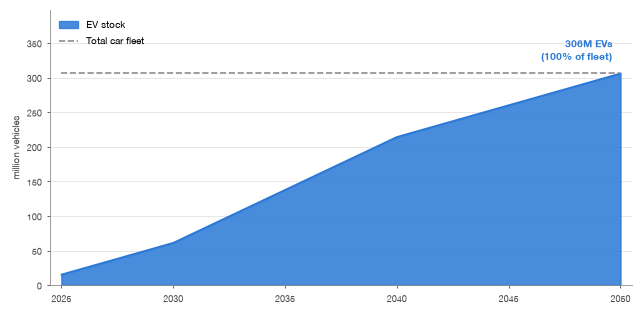

In [3]:
stock_m = turnover["ev_stock"] / M
fleet_m = turnover["fleet_total"] / M

fig, (ax,) = plotting.page_figure(style)
ax.fill_between(years, stock_m, color=BLUE, alpha=0.85, label="EV stock")
ax.plot(years, stock_m, color=BLUE)
ax.plot(years, fleet_m, color=ink["muted"], linestyle="--", label="Total car fleet")

ax.annotate(
    f"{stock_m.iloc[-1]:,.0f}M EVs\n({turnover['ev_share'].iloc[-1]:.0%} of fleet)",
    xy=(years[-1], stock_m.iloc[-1]), xytext=(-6, 8), textcoords="offset points",
    ha="right", va="bottom", color=BLUE, fontweight="bold",
)
# No title: the caption is written where the figure is published.
plotting.style_panel(ax, style, title=None, ylabel="Million vehicles")
# Headroom for the legend and the end annotation, which both sit over the fleet
# line: the fill reaches it by 2050, so there is nowhere inside the data for them.
ax.set_ylim(0, fleet_m.max() * 1.3)
ax.margins(x=0.02)
legend = ax.legend(frameon=False, loc="upper left")
plotting.save_figure(fig, figures_dir, "ev_stock", style, (legend,))

## Annual EV turnover

Bars are total sales each year. The line is the replacement component —
retirements that must be re-manufactured to keep the fleet on the road. It
climbs with the fleet: the more EVs on the road, the more retire and need
replacing each year, on top of the sales still growing the fleet.

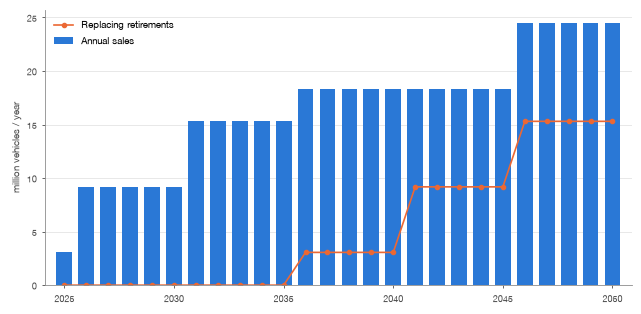

In [4]:
sales_m = turnover["ev_sales"] / M
retire_m = turnover["retirements"] / M

fig, (ax,) = plotting.page_figure(style)
ax.bar(years, sales_m, color=BLUE, width=0.72, label="Annual sales")
ax.plot(years, retire_m, color=ORANGE, marker="o", markersize=3,
        label="Replacing retirements")

plotting.style_panel(ax, style, title=None, ylabel="Million vehicles / year")
ax.margins(x=0.02)
legend = ax.legend(frameon=False, loc="upper left")
plotting.save_figure(fig, figures_dir, "ev_sales_annual", style, (legend,))

## Cumulative EV sales

Running total of vehicles built over the window — the manufacturing volume the
metal-demand step turns into mineral demand.

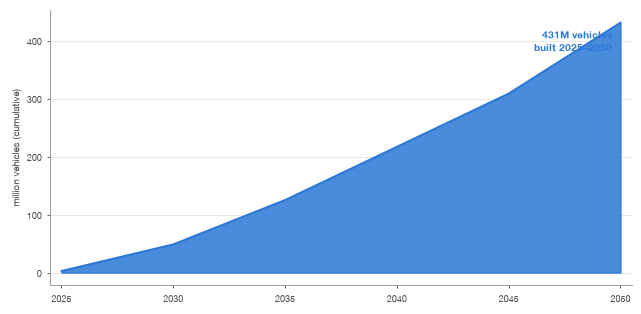

In [5]:
cum_m = turnover["ev_sales_cumulative"] / M

fig, (ax,) = plotting.page_figure(style)
ax.fill_between(years, cum_m, color=BLUE, alpha=0.85)
ax.plot(years, cum_m, color=BLUE)
ax.annotate(
    f"{cum_m.iloc[-1]:,.0f}M vehicles\nbuilt {years[0]}–{years[-1]}",
    xy=(years[-1], cum_m.iloc[-1]), xytext=(-6, -4), textcoords="offset points",
    ha="right", va="top", color=BLUE, fontweight="bold",
)
plotting.style_panel(
    ax, style, title=None, ylabel="Million vehicles (cumulative)"
)
ax.margins(x=0.02)
plotting.save_figure(fig, figures_dir, "ev_sales_cumulative", style)